# Assignment 06: A First-Principles Species Distribution Model

## BIO597 Spatial Analysis of Biodiversity

This assignment asks you to build and interpret a simple one-variable species distribution model without using an SDM package. You will choose one amphibian species, describe the environmental values at its occurrence records, compare those values with background environments, create a suitability curve, and project that curve across Maine.

## Deliverable

Submit a completed notebook with code, maps, plots, and short written interpretations. Your goal is to show that you understand the moving parts of an SDM before we use more automated modeling tools.

## Learning goals

By the end of this assignment, you should be able to:

* describe the difference between occurrence, background, and absence data
* extract one raster predictor at species occurrence records
* compare used environments with available environments
* create a simple environmental suitability score
* project a suitability score across raster space
* explain why a conceptual SDM is not the same as a validated prediction model

## Data

Use:

* `Amphibians_ME/Amphibians_ME.csv` for occurrence records
* `/home/jovyan/shared-readwrite/bioclim/` for one environmental variable of your choice that is NOT mean annual temperature
* `../labs/ME_ShapeFiles/Maine_State_Boundary.shp` for the Maine boundary

You may use the same species as the lab or choose a different species with at least 100 usable records.

## 1. Import packages

Import `pandas`, `geopandas`, `rioxarray`, `xarray`, `numpy`, `matplotlib.pyplot`, and `Path`.

In [2]:
pip install rioxarray

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import packages here.

from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray as rxr
import xarray as xr

## 2. Load and combine the Maine boundary

Read the Maine state boundary shapefile, inspect its CRS and shape, and dissolve it to one row.

In [4]:
boundary_path = "../labs/ME_ShapeFiles/Maine_State_Boundary.shp"

# Read the boundary.
# Print its shape and CRS.
# Dissolve it to one row.

maine_boundary = gpd.read_file(boundary_path)
print(maine_boundary.shape)
print(maine_boundary.crs)

(6204, 10)
EPSG:4326


## 3. Open and clip environmental data

Select one environmental variable of your choosing that is NOT mean annual temperature. You can choose one you think will work well or one you think is less important for the study organism. Open the variable .tif file with `masked=True`, clip it to Maine, and remove the band dimension with `squeeze()`.


In [5]:
bioclim_path = Path("/home/jovyan/shared/bioclim")
bio18_path = bioclim_path / "wc2.1_2.5m_bio_18.tif"
# bio18 is the precipitation of the warmest quarter in mm

# Open bio1 with rxr.open_rasterio().

bio18_path = rxr.open_rasterio(
    bio18_path,
    masked=True,
)

# Clip it to the dissolved Maine boundary.
# Squeeze out the band dimension.
# Convert to degrees Celsius if needed. 

bio18_maine = bio18_path.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
).squeeze()

# did not need to convert as bio18 is measured in mm, not c

## 4. Map your environmental variable

Create a map of the clipped temperature raster. Include a title.

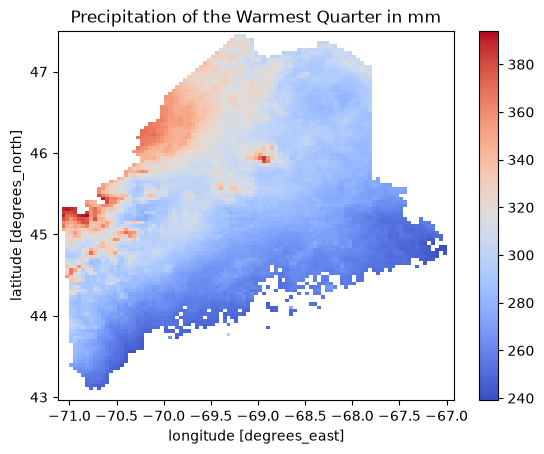

In [6]:
# Plot annual mean temperature for Maine.

bio18_maine.plot(cmap="coolwarm")
plt.title("Precipitation of the Warmest Quarter in mm")
plt.show()

## 5. Load and prepare amphibian occurrence records

Read the tab-delimited amphibian file. Keep `gbifID`, `species`, longitude, latitude, coordinate uncertainty, and year. Convert coordinates to numeric values and remove records missing species or coordinates.

In [7]:
amphibians = pd.read_csv(
    "Amphibians_ME/Amphibians_ME.csv",
    sep="\t",
    low_memory=False,
)

columns_to_keep = [
    "gbifID",
    "species",
    "decimalLongitude",
    "decimalLatitude",
    "coordinateUncertaintyInMeters",
    "year",
]

# Keep only columns_to_keep.
# Convert longitude and latitude to numeric values.
# Drop records missing species, longitude, or latitude.

amphibians = amphibians[columns_to_keep].copy()
amphibians["decimalLognitude"] = pd.to_numeric(amphibians["decimalLongitude"], errors="coerce")
amphibians["decimalLatitude"] = pd.to_numeric(amphibians["decimalLatitude"], errors="coerce")

amphibians = amphibians.dropna(subset=["species", "decimalLongitude", "decimalLatitude"]).copy()

amphibians = amphibians[amphibians["coordinateUncertaintyInMeters"] < 200]

## 6. Choose one species

Display the most common species, then choose one species with at least 100 records. Store its scientific name as `target_species`.

In [8]:
# Display species counts.

amphibians["species"].value_counts().head(10)

species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Name: count, dtype: int64

In [9]:
target_species = "Pseudacris crucifer"

# Filter the occurrence table to your target species.
# Display the number of records and the first five rows.

presence = amphibians.loc[amphibians["species"] == target_species].copy()
print(target_species)
print(presence.shape)
presence.head()

Pseudacris crucifer
(1839, 7)


,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year,decimalLognitude
15,6520620737,Pseudacris crucifer,-70.850360,44.272807,12.0,2026.0,-70.850360
29,6520534469,Pseudacris crucifer,-69.968868,43.887461,15.0,2026.0,-69.968868
59,6520223742,Pseudacris crucifer,-68.459888,45.305901,15.0,2026.0,-68.459888
65,6520169363,Pseudacris crucifer,-68.567862,44.303792,6.0,2026.0,-68.567862
111,6519813217,Pseudacris crucifer,-70.073326,44.592665,8.0,2026.0,-70.073326


**Why did you choose this species?** Include one sentence about record count and one sentence about why it may or may not be appropriate for this simple model. Spring peepers are common frogs and are known by their calls which is probably why they have such a high record count. Spring peepers may not be appropriate for a simple model because I chose bio18 and spring peepers breeding is most likely over by the time the warmest parts of the summer happen so precipitation during those months may or may not impact spring peepers breeding. 

## 7. Create an occurrence GeoDataFrame

Use longitude and latitude to create point geometry. Assign `EPSG:4326`. Confirm that the occurrence CRS and raster CRS are compatible.

In [10]:
# Create presence_gdf.
# Print the occurrence CRS and raster CRS.

presence_gdf = gpd.GeoDataFrame(
    presence,
    geometry=gpd.points_from_xy(
        presence["decimalLongitude"],
        presence["decimalLatitude"],
    ),
    crs="EPSG:4326",
)

print("Occurence CRS:", presence_gdf.crs)
print("Raster CRS:", bio18_maine.rio.crs)


Occurence CRS: EPSG:4326
Raster CRS: EPSG:4326


**CRS check:** Explain why coordinate systems matter before extracting raster values at points: The raster cells and coordinating systems must match perfectly for the overlay or else it will give you incorrect data or just not work at all.

## 8. Extract environment at occurrence points

Create `xarray.DataArray` objects for point longitude and latitude. Use `.sel(..., method="nearest")` to extract BIO1 values at occurrence records. Add the extracted values to a column named `bio1_c`.

In [11]:
# Create point_x and point_y.
# Extract temperature values.
# Add them to presence_gdf as bio1_c.
# Drop records with missing bio1_c.
# Rebuild point_x and point_y after dropping missing values.

point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

presence_precip = bio18_maine.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

presence_gdf["bio18_mm"] = presence_precip.values
presence_gdf = presence_gdf.dropna(subset=["bio18_mm"]).copy()

point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

presence_gdf[["species", "decimalLongitude", "decimalLatitude", "bio18_mm"]].head()

,species,decimalLongitude,decimalLatitude,bio18_mm
15,Pseudacris crucifer,-70.850360,44.272807,295.0
29,Pseudacris crucifer,-69.968868,43.887461,254.0
59,Pseudacris crucifer,-68.459888,45.305901,283.0
111,Pseudacris crucifer,-70.073326,44.592665,292.0
129,Pseudacris crucifer,-67.110953,44.755056,241.0


## 9. Summarize occurrence environment

Calculate the count, mean, standard deviation, minimum, and maximum of `bio1_c` at occurrence records.

In [12]:
# Summarize occurrence temperature values.

presence_mean = presence_gdf["bio18_mm"].mean()
presence_sd = presence_gdf["bio18_mm"].std()

print(f"Number of usable records: {len(presence_gdf)}")
print(f"Mean occurence precipitation: {presence_mean:.2f} mm")
print(f"SD of occurence precipitation: {presence_sd:.2f} mm")
print(f"Minimum occurence precipitation: {presence_gdf['bio18_mm'].min():.2f} mm")
print(f"Maximum occurence precipitation: {presence_gdf['bio18_mm'].max():.2f} mm")

Number of usable records: 1722
Mean occurence precipitation: 262.59 mm
SD of occurence precipitation: 15.08 mm
Minimum occurence precipitation: 241.00 mm
Maximum occurence precipitation: 360.00 mm


**Interpretation:** In two or three sentences, describe the environmental range represented by your species records. These records span from a minimum of 241 mm to a max of 360 mm. The mean occurence shows that the majority of the 1722 observations happen in a tight cluster around 262.59 mm which indicates a possible niche restriction where it can tolerate higher or lower precipitation but has a preference.

## 10. Sample background environment

Create a random sample of up to 5,000 valid cells from Maine for your environmental variable. Use a random seed so your results are reproducible.

In [13]:
rng = np.random.default_rng(597)

# Create an array of valid raster environmental values.
# Randomly sample up to 5000 cells without replacement.
# Print the background sample size, mean, and standard deviation.

valid_precipitation = bio18_maine.values
valid_precipitation = valid_precipitation[np.isfinite(valid_precipitation)]

background_precip = rng.choice(
    valid_precipitation,
    size=min(5000, valid_precipitation.size),
    replace=False,
)

print(f"Background sample size: {len(background_precip)}")
print(f"Mena background precipitation: {background_precip.mean():.2f} mm")
print(f"SD background temperature: {background_precip.std():.2f} mm")


Background sample size: 5000
Mena background precipitation: 291.40 mm
SD background temperature: 27.54 mm


## 11. Compare occurrence and background environments

Make overlapping histograms of occurrence environment and background environment. Use density-scaled histograms so the shapes can be compared even though the sample sizes differ.

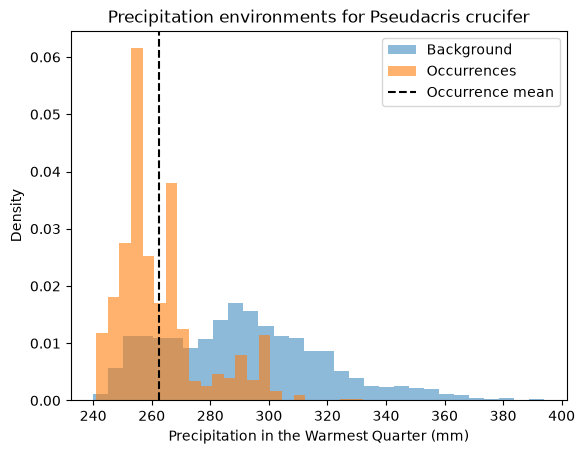

In [14]:
# Create an overlapping histogram of background and occurrence temperatures.

plt.hist(background_precip, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_gdf["bio18_mm"], bins=30, alpha=0.6, density=True, label="Occurrences")
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Precipitation in the Warmest Quarter (mm)")
plt.ylabel("Density")
plt.title(f"Precipitation environments for {target_species}")
plt.legend()
plt.show()

**Interpretation:** Does your species appear to use a narrow or broad subset of available environmental space? Explain using your plot. It looks like a narrow subset of environmental data as the data points are clustered together in one small section of the total available environmental space.

## 12. Define a suitability function

Write a function that takes `observed`, `optimum`, and `tolerance` and returns:

```python
np.exp(-0.5 * ((observed - optimum) / tolerance) ** 2)
```

This creates a score near 1 when observed environment is close to the optimum and closer to 0 as temperature gets farther away.

In [22]:
def precipitation_suitability(observed, optimum, tolerance):
    # Replace this comment with the suitability calculation.
    z = (observed - optimum) / tolerance
    return np.exp(-0.5 * z**2)

## 13. Plot your suitability curve

Use the mean occurrence environmental value as the optimum and the standard deviation of occurrence as the tolerance. Plot suitability across the full range of Maine BIO1 values.

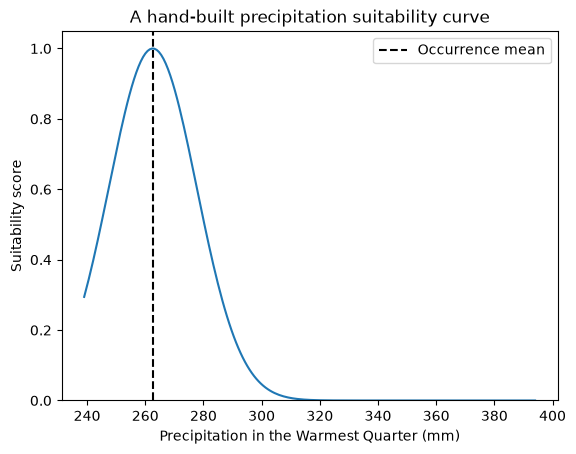

In [23]:
# Calculate presence_mean and presence_sd.
# Create a sequence of environmental values across the raster range.
# Calculate suitability for those values.
# Plot the curve.

x_precip = np.linspace(
    float(np.nanmin(bio18_maine.values)),
    float(np.nanmax(bio18_maine.values)),
    200,
)

suitability_curve = precipitation_suitability(
    x_precip,
    optimum=presence_mean,
    tolerance=presence_sd,
)

plt.plot(x_precip, suitability_curve)
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Precipitation in the Warmest Quarter (mm)")
plt.ylabel("Suitability score")
plt.ylim(0, 1.05)
plt.title("A hand-built precipitation suitability curve")
plt.legend()
plt.show()

**Interpretation:** What value receives the highest suitability score? What does the tolerance control? The absolute peak of the bell curve (which should be 1). The tolerance controls the width of the suitability curve. 

## 14. Project suitability across Maine

Apply your suitability function to every cell in the environmental raster. Keep missing raster cells missing.

In [24]:
# Use xr.apply_ufunc() to apply environmental_suitability to the raster.
# Store the result as suitability.
# Mask cells where the environmental raster is missing.

suitability = xr.apply_ufunc(
    precipitation_suitability,
    bio18_maine,
    presence_mean,
    presence_sd,
)

suitability = suitability.where(np.isfinite(bio18_maine))
suitability = suitability.rio.write_crs(bio18_maine.rio.crs)
suitability.name = "precipitation_suitability"
suitability

<xarray.DataArray 'precipitation_suitability' (y: 109, x: 101)> Size: 88kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(109, 101))
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  5608
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  0
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 15. Map suitability

Create a continuous suitability map with values from 0 to 1.

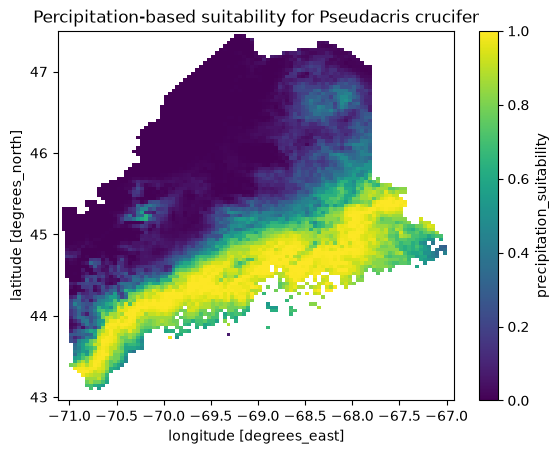

In [25]:
# Plot the suitability raster.

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Percipitation-based suitability for {target_species}")
plt.show()

## 16. Overlay occurrence points

Plot your suitability raster and overlay the occurrence points. This is a visual check, not a formal validation.

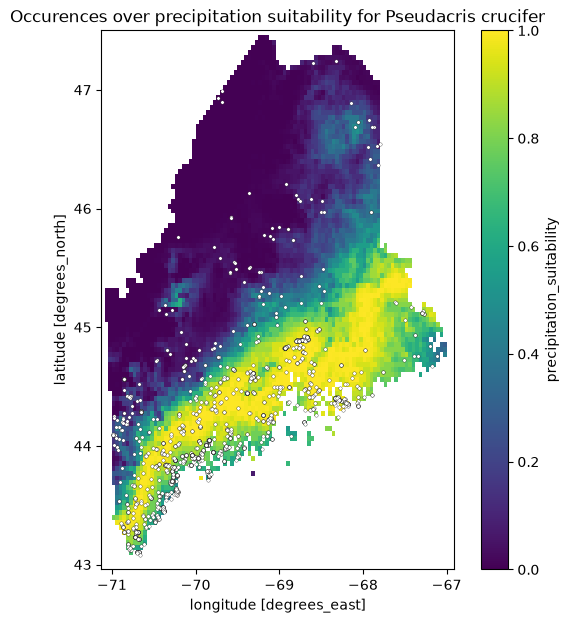

In [26]:
# Plot suitability and overlay presence_gdf points.

fig, ax = plt.subplots(figsize=(7, 7))
suitability.plot(ax=ax, vmin=0, vmax=1, cmap="viridis")
presence_gdf.plot(ax=ax, markersize=6, color="white", edgecolor="black", linewidth=0.2)
ax.set_title(f"Occurences over precipitation suitability for {target_species}")
plt.show()

**Visual check:** Do occurrence points generally fall in areas with higher predicted suitability? Describe any mismatch you see. Yes, most points fall within the higher predicted suitability with a few scattering in central to Northern Maine. This is most likely from vernal pools or some sort of water source in those areas. 

## 17. Compare occurrence and background suitability scores

Extract suitability at occurrence records. Also calculate suitability for your background environmental values. Compare the two distributions with histograms.

Mean occurrence suitability: 0.742
Mean background suitability: 0.362


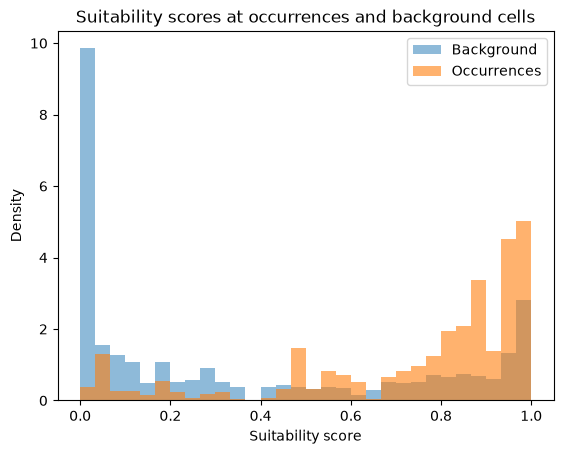

In [27]:
# Extract suitability at occurrence points.
# Calculate suitability for background environmental values.
# Print mean occurrence suitability and mean background suitability.
# Plot overlapping histograms.

presence_suitability = suitability.sel(
    x=point_x,
    y=point_y,
    method="nearest",
).values

background_suitability = precipitation_suitability(
    background_precip,
    optimum=presence_mean,
    tolerance=presence_sd,
)

print(f"Mean occurrence suitability: {np.nanmean(presence_suitability):.3f}")
print(f"Mean background suitability: {np.nanmean(background_suitability):.3f}")

plt.hist(background_suitability, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_suitability, bins=30, alpha=0.6, density=True, label="Occurrences")
plt.xlabel("Suitability score")
plt.ylabel("Density")
plt.title("Suitability scores at occurrences and background cells")
plt.legend()
plt.show()

**Interpretation:** Did your model score occurrence records higher than background locations? What would it mean if it did not? Occurence records should be close to the peak of the bell curve which is 1. If the occurrences were not near 1, that would mean that this model has no predictive power. 

## 18. Change the tolerance

Create two additional suitability rasters: one with half the observed standard deviation and one with twice the observed standard deviation. Map all three side by side.

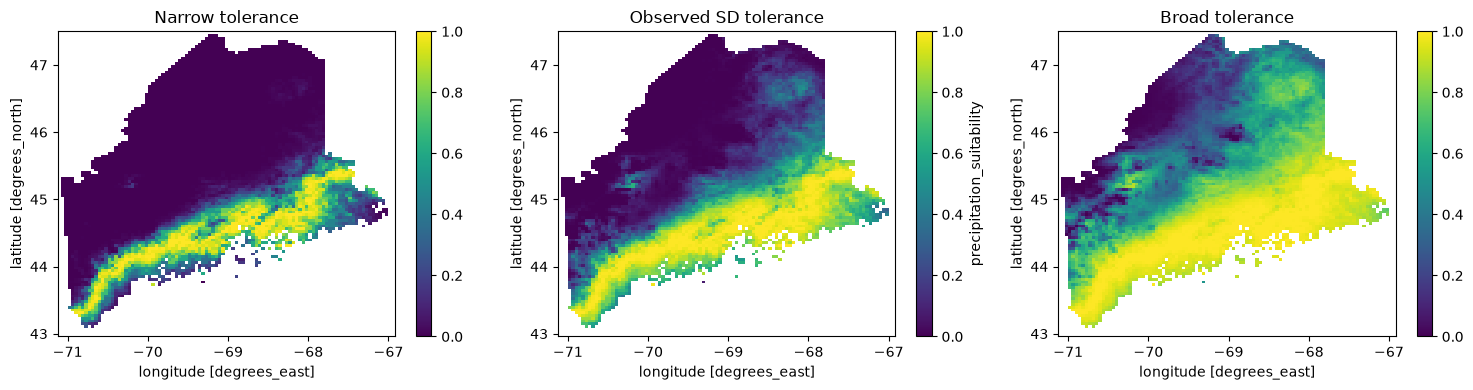

In [28]:
# Create narrow_suitability using presence_sd / 2.
# Create broad_suitability using presence_sd * 2.
# Plot narrow, original, and broad suitability maps side by side.

narrow_suitability = xr.apply_ufunc(
    precipitation_suitability,
    bio18_maine,
    presence_mean,
    presence_sd / 2,
).where(np.isfinite(bio18_maine))

broad_suitability = xr.apply_ufunc(
    precipitation_suitability,
    bio18_maine,
    presence_mean,
    presence_sd * 2,
).where(np.isfinite(bio18_maine))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
narrow_suitability.plot(ax=axes[0], vmin=0, vmax=1, cmap="viridis")
axes[0].set_title("Narrow tolerance")
suitability.plot(ax=axes[1], vmin=0, vmax=1, cmap="viridis")
axes[1].set_title("Observed SD tolerance")
broad_suitability.plot(ax=axes[2], vmin=0, vmax=1, cmap="viridis")
axes[2].set_title("Broad tolerance")
plt.tight_layout()
plt.show()

**Interpretation:** How does tolerance affect the predicted distribution? Which tolerance seems most defensible for your species, and why? Tolerance affects the predicted distribution by either having a low tolerance which is a narrow curve or a high tolerance which would have a wide curve. I would think a broad tolerance would be acceptable for the spring peeper as peepers are highly resilient species and found commonly throughout Maine. Because of this, the species would have a wider tolerane because the peepers are so widespread.

## 19. Threshold the continuous map

Convert your continuous suitability map to a binary suitable/unsuitable map using a threshold of your choice. Report the fraction of Maine climate cells labeled suitable.

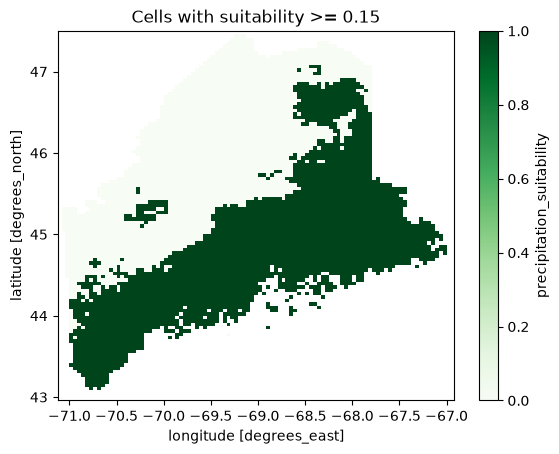

Fraction of Maine climate cells labeled suitable: 52.63%


In [32]:
threshold = 0.15

# Create a binary suitability map.
# Plot it.
# Calculate the fraction of non-missing cells labeled suitable.

suitable_binary = suitability >= threshold
suitable_binary = suitable_binary.where(np.isfinite(bio18_maine))

suitable_binary.plot(cmap="Greens")
plt.title(f"Cells with suitability >= {threshold}")
plt.show()

suitable_fraction = float(suitable_binary.mean(skipna=True))
print(f"Fraction of Maine climate cells labeled suitable: {suitable_fraction:.2%}")

**Threshold justification:** Why did you choose this threshold? How would the map change with a lower or higher threshold? I chose a median threshold, increasing the threshold reduces the range whereas decreaasing the threshold increases the range. For the peepers, a decreased threshold may be more appriopriate because they are a widespread species. 

## 20. Save your outputs

Save your continuous suitability raster as `Assignment06_suitability.tif`. Save a CSV containing your occurrence records and extracted BIO1 values as `Assignment06_presence.csv`.

In [33]:
# Save the suitability raster.
# Save the occurrence table with extracted temperature values.

suitability.rio.to_raster("Assignment06_suitability.tif")

presence_table = presence_gdf.drop(columns="geometry")
presence_table["precipitation_suitability"] = presence_suitability
presence_table.to_csv("Assignment06_presence.csv", index=False)

## Final reflection

Answer each question in two or three sentences.

1. In this exercise, what information came from occurrence records and what information came from the environmental raster? From the occurence records, we got the biological preferences of the species (we got the optimum and the tolerance). For the environmental raster, we got the geographic data and the constraints of Maine as a boundary.
2. Why did we compare occurrence environment with background environment? It shows that the species is actively selecting for habitat and to accurately measure the model's predictive power. This can be useful in determing if the peeper is actively selecting for specific conditions and it allows for a good model to assign high suitability scores to known occurence records and baseline scores to random background locations.
3. Why is this suitability score not the same as probability of presence? A suitability score is the measure of how environmental conditions match a species' preference whereas the probability of presence is an actual statistical likelihood that the species actually occupies that specific spot. This means that even if there is a certain habitat that has the perfect environmental conditions does not mean there is 100% a peeper is there.
4. Name two ecological or sampling processes ignored by this one-variable model. Predation is not measured and spatial sampling bias. The environmental conditions for a peeper may be perfect but the realized niche but if there are predators like bull frog larvae are present, the peepers will be driven out. And we have spoken about spatial sampling bias a lot during our assignments as easy access roads or high human traffic areas are more likely to actually see and report amphibian sightings which is a sampling bias.
5. What would a full SDM package add beyond this first-principles workflow? This first-principle workflow is incredibly simple (for obvious reasons) and we are really only looking at one variable. A full SDM package would become more complicated and would handle multiple variables at once. 

## Submit your work

Run the notebook from top to bottom. Make sure all maps, plots, saved files, and written answers are complete. Then commit and push the completed notebook to your class GitHub repository.

```bash
git add docs/assignments/Assignment-06-FirstPrinciplesSDM.ipynb
git commit -m "Complete first principles SDM assignment"
git push
```